# DISCO-EB: the differentiable Boltzmann engine

[cosmoprimo](https://github.com/cosmodesi/cosmoprimo) can delegate the linear Einstein–Boltzmann
solve to [DISCO-EB](https://github.com/ohahn/DISCO-EB), a JAX implementation that is
**autodifferentiable end to end**. Select it with `engine='discoeb'`.

DISCO-EB is *linear-only* (there is no `Harmonic`/CMB section) and models
$\Lambda\mathrm{CDM} + (w_0, w_a)$ + curvature + one degenerate family of massive neutrinos.
This notebook walks through the sections it supports and finishes with derivatives of $P(k)$.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import jax

from cosmoprimo import Cosmology

print('jax', jax.__version__, '| x64:', jax.config.jax_enable_x64)

/Users/dforero/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/jj/2h7pv3_90z3djxhrlqxjvsxw0000gn/T/matplotlib-ljut7auu because there was an issue with the default path (/Users/dforero/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/dforero/.cache/fontconfig
	/Users/dforero/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/dforero/.cache/fontconfig
	/Users/dforero/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/dforero/.cache/fontconfig
	/Users/dforero/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/dforero/.cache/fontconfig
	/Users/dforero/.fontconfig


Matplotlib is building the font cache; this may take a moment.


jax 0.10.0 | x64: True


## Selecting the engine

As for any other engine, `Cosmology(engine='discoeb', ...)` accepts the usual cosmological
parameters; solver precision is passed through `extra_params` (see
`cosmoprimo.discoeb.DISCOEBEngine` for the full list). Here we use deliberately cheap settings so
the notebook runs in about a minute: 64 wavenumbers, two redshifts and 256 thermal-history
points.

In [2]:
PARAMS = dict(Omega_cdm=0.25, Omega_b=0.05, h=0.67742, A_s=2.1064e-9, n_s=0.96822,
              m_ncdm=[0.06], N_eff=3.044, T_cmb=2.7255)

# DISCO-EB precision parameters: fewer k, fewer thermal points, loose-ish ODE tolerances.
EXTRA = dict(nk=64, kmin=1e-4, kmax=2., z=[0., 1.], num_thermo=256, rtol=1e-4, atol=1e-4)

cosmo = Cosmology(engine='discoeb', extra_params=EXTRA, **PARAMS)
cosmo.engine.name, cosmo['Omega_m'], cosmo['H0']

('discoeb', np.float64(0.3014036574154018), np.float64(67.742))

### Execution and jitting

The engine wraps **the whole background + perturbation solve** in a single `jax.jit`
(`cosmoprimo.discoeb._discoeb_solve_jit`). The compiled callable is cached per set of static
settings and shared across engine instances, so a parameter sweep pays for one compilation only.

Two things are worth knowing:

- `max_steps` is a **cap** on the adaptive ODE solver (a compile-time constant), *not* a step
  count: lowering it never makes a solve faster, it only risks a step-limit error.
- To trade accuracy for speed, reduce `nk`, `num_thermo`, the Boltzmann truncations
  (`lmaxg`, `lmaxgp`, `lmaxr`, `lmaxnu`, `nqmax`), or loosen `rtol`/`atol`.

In [3]:
# First call JIT-compiles the background + perturbation solve; later calls reuse it.
t0 = time.time()
fo = cosmo.get_fourier()
print(f'first P(k) call (incl. compilation): {time.time() - t0:.1f} s')

t0 = time.time()
cosmo.get_fourier()
print(f'same settings again:                {time.time() - t0:.2f} s')

first P(k) call (incl. compilation): 9.5 s
same settings again:                0.00 s


## Background

DISCO-EB's background is the standard Friedmann evolution, so the engine reuses cosmoprimo's
well-tested `DefaultBackground` (distances, growth factor/rate, ages, energy densities).

In [4]:
ba = cosmo.get_background()
print(f"H0              = {ba.H0:.2f} km/s/Mpc")
print(f"age             = {ba.age:.3f} Gyr")
print(f"Omega_m         = {ba.Omega0_m:.4f}")
print(f"growth rate f(0)= {ba.growth_rate(0.):.4f}")
print(f"chi(z=1)        = {ba.comoving_radial_distance(1.):.1f} Mpc/h")

H0              = 67.74 km/s/Mpc
age             = 13.893 Gyr
Omega_m         = 0.3014
growth rate f(0)= 0.5141
chi(z=1)        = 2310.6 Mpc/h


## Thermodynamics

From DISCO-EB's thermal history (RECFAST by default, MB95 available through
`extra_params={'thermo_module': 'MB95'}`): recombination and drag redshifts, the sound horizon,
and the electron fraction.

In [5]:
th = cosmo.get_thermodynamics()
print(f"z_star          = {th.z_star:.1f}")
print(f"z_drag          = {th.z_drag:.1f}")
print(f"r_s(z_drag)     = {th.rs_drag:.2f} Mpc/h")
print(f"100 * theta_star= {100 * th.theta_star:.3f}")
print(f"x_e(z=0)        = {th.x_e(0.):.2e}")
print(f"x_e(z=1100)     = {th.x_e(1100.):.3f}")

z_star          = 1094.9
z_drag          = 1064.2
r_s(z_drag)     = 99.96 Mpc/h
100 * theta_star= 1.031
x_e(z=0)        = 1.61e-04
x_e(z=1100)     = 0.133


## Primordial

DISCO-EB takes a power-law primordial spectrum; running of the spectral index is not implemented
(`alpha_s = beta_s = 0`).

In [6]:
pm = cosmo.get_primordial()
print(f"A_s = {pm.A_s:.6e},  n_s = {pm.n_s},  alpha_s = {pm.alpha_s},  k_pivot = {pm.k_pivot:.3f} h/Mpc")

A_s = 2.106400e-09,  n_s = 0.96822,  alpha_s = 0.0,  k_pivot = 0.074 h/Mpc


## Linear matter power spectrum

`get_fourier().table(...)` returns `k` in $h$/Mpc and $P(k)$ in $(h^{-1}\mathrm{Mpc})^3$, for the
requested species (`delta_m`, `delta_cb`, `theta_cb`, …). `pk_interpolator` gives a jax-friendly
2D interpolator, which is what `sigma8` and `sigma(r, z)` are built on.

In [7]:
k, z, pk = fo.table(of='delta_m')
print('k grid:', k.shape, f'[{k[0]:.1e}, {k[-1]:.1e}] h/Mpc')
print('redshifts:', z)
print(f'sigma8(z=0)   = {float(fo.sigma8_m):.4f}')
print(f'sigma8(z=1)   = {float(fo.sigma8_z(1.)):.4f}')
print(f'sigma(r=8, z=0) = {float(fo.sigma_rz(8., 0.)):.4f}')

k grid: (64,) [1.0e-04, 2.0e+00] h/Mpc
redshifts: [0. 1.]
sigma8(z=0)   = 0.7877
sigma8(z=1)   = 0.4822
sigma(r=8, z=0) = 0.7877


### Comparison with Eisenstein & Hu (and CLASS/CAMB if installed)

DISCO-EB is a full Boltzmann solve, so for the same model it should agree with a full CLASS/CAMB
solve at the ~1% level, and track the analytic Eisenstein & Hu fit to roughly the fit's own
accuracy (~10-15%). CLASS/CAMB are drawn only if those engines are installed.

class: not available (ModuleNotFoundError)


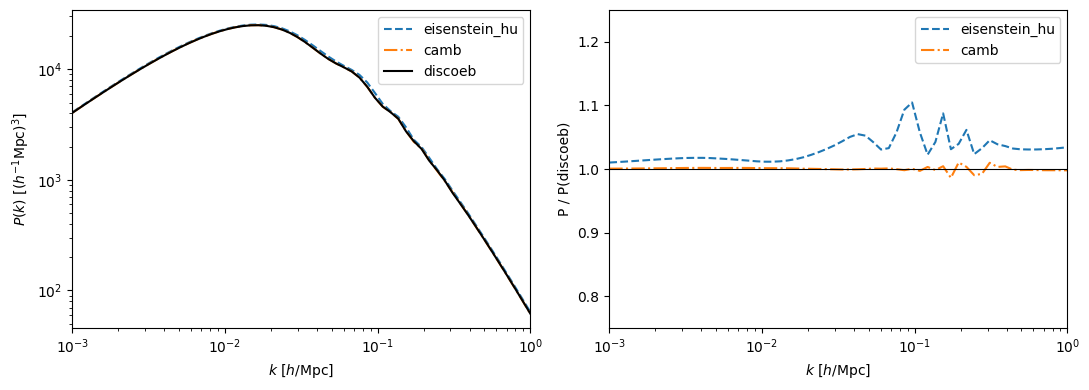

In [8]:
kq = np.geomspace(1e-3, 1., 60)

def other_pk(engine, params):
    return Cosmology(engine=engine, **params).get_fourier().pk_interpolator(of='delta_m')

# Eisenstein & Hu has no massive neutrinos, so compare the same massless-neutrino model.
params_nu = {name: value for name, value in PARAMS.items() if name != 'm_ncdm'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for engine, model, ls in [('eisenstein_hu', params_nu, '--'), ('class', PARAMS, ':'), ('camb', PARAMS, '-.')]:
    try:
        axes[0].loglog(kq, other_pk(engine, model)(kq, z=0.), ls, label=engine)
    except Exception as exc:
        print(f'{engine}: not available ({type(exc).__name__})')

axes[0].loglog(kq, fo.pk_interpolator(of='delta_m')(kq, z=0.), 'k-', label='discoeb')
axes[0].set(xlabel=r'$k$ [$h$/Mpc]', ylabel=r'$P(k)$ [$(h^{-1}$Mpc$)^3$]', xlim=(1e-3, 1.))
axes[0].legend()

# ratio to DISCO-EB
p_dis = np.asarray(fo.pk_interpolator(of='delta_m')(kq, z=0.))
for engine, model, ls in [('eisenstein_hu', params_nu, '--'), ('class', PARAMS, ':'), ('camb', PARAMS, '-.')]:
    try:
        axes[1].semilogx(kq, np.asarray(other_pk(engine, model)(kq, z=0.)) / p_dis, ls, label=engine)
    except Exception:
        pass
axes[1].axhline(1., color='k', lw=0.8)
axes[1].set(xlabel=r'$k$ [$h$/Mpc]', ylabel='P / P(discoeb)', ylim=(0.75, 1.25), xlim=(1e-3, 1.))
axes[1].legend()
plt.tight_layout()

## Cross-spectra and velocities

Any pair of computed fields can be requested: `('delta_cb', 'theta_cb')` is the density–velocity
cross-spectrum, and `theta_m` is the velocity divergence in units of the conformal Hubble rate
(so $P_{\theta\theta} = f^2 P_{\delta\delta}$ on large scales).

In [9]:
for of in ['delta_cb', ('delta_cb', 'theta_cb'), 'theta_m']:
    kk, zz, pkk = fo.table(of=of)
    print(f'{str(of):24s} {pkk.shape}  P(k=1e-3, z=0) = {pkk[0, 0]:.3e}')

# P_theta_theta / P_delta_delta ~ f^2 at low k
p_dd = np.asarray(fo.table(of='delta_m')[2][0, 0])
p_tt = np.asarray(fo.table(of='theta_m')[2][0, 0])
print(f'f(k=1e-3, z=0) ~ sqrt(P_tt / P_dd) = {np.sqrt(p_tt / p_dd):.4f}')

delta_cb                 (64, 2)  P(k=1e-3, z=0) = 4.430e+02
('delta_cb', 'theta_cb') (64, 2)  P(k=1e-3, z=0) = -2.279e+02
theta_m                  (64, 2)  P(k=1e-3, z=0) = 1.172e+02
f(k=1e-3, z=0) ~ sqrt(P_tt / P_dd) = 0.5143


## Differentiability

DISCO-EB's headline feature: `params -> P(k)` is traceable, so cosmoprimo's standard jax pattern
gives Jacobians of the matter power spectrum. We differentiate the **interpolated** spectrum that
`get_fourier().pk_interpolator(...)` returns -- i.e. exactly what `sigma8` and `sigma(r, z)`
evaluate -- so the whole chain (solver, `Fourier` section, interpax interpolator) is covered.

One requirement: build the `Cosmology` (and therefore its interpolator) **inside** the function you
differentiate. The perturbation solution is cached on the engine and the interpolator on the
`Fourier` section, so an interpolator created once from concrete parameters holds concrete node
values and has no dependence on the traced parameters -- differentiating it returns an identical
zero.

Out-of-bounds $k$ is filled with `nan` -- and that `nan` now propagates into the derivative, so an out-of-range evaluation returns `nan` rather than a plausible-looking all-zero Jacobian.


interpolated P(k) Jacobian: finite, and non-zero for all parameters: True


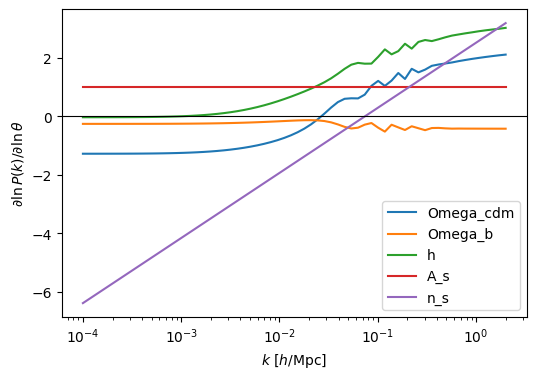

In [10]:
keys = ['Omega_cdm', 'Omega_b', 'h', 'A_s', 'n_s']
p0 = {name: PARAMS[name] for name in keys}
k_hmpc = np.asarray(fo.table(of='delta_m')[0])

def pk_interp_of(params):
    # NB: the Cosmology (and its interpolator) is built *inside* the traced function.
    cosmo = Cosmology(engine='discoeb', extra_params=EXTRA, **params)
    return cosmo.get_fourier().pk_interpolator(of='delta_m')(k_hmpc, z=0.)

jac = jax.jacfwd(pk_interp_of)(p0)          # forward mode (DISCO-EB uses DirectAdjoint)
pk0 = np.asarray(pk_interp_of(p0))
g = np.asarray(jac['Omega_cdm'])
assert np.all(np.isfinite(g)) and np.any(g != 0.), 'interpolated Jacobian must be finite and non-zero'
print('interpolated P(k) Jacobian: finite, and non-zero for all parameters:',
      all(np.any(np.asarray(jac[name]) != 0.) for name in keys))

plt.figure(figsize=(6, 4))
for name in keys:
    plt.semilogx(k_hmpc, np.asarray(jac[name]) * p0[name] / pk0, label=name)
plt.axhline(0., color='k', lw=0.8)
plt.xlabel(r'$k$ [$h$/Mpc]')
plt.ylabel(r'$\partial \ln P(k) / \partial \ln \theta$')
plt.legend()


In [11]:
# Cross-check against a central finite difference on Omega_cdm.  Use a robust statistic: the pointwise
# *maximum* is dominated by the k where dP/dOmega_cdm crosses zero, where a relative error is not
# meaningful.  Adaptive-solver noise enters the finite difference as ~rtol / eps.
eps = 1e-3
g_auto = np.asarray(jac['Omega_cdm'])
g_fd = (np.asarray(pk_interp_of(dict(p0, Omega_cdm=p0['Omega_cdm'] + eps)))
        - np.asarray(pk_interp_of(dict(p0, Omega_cdm=p0['Omega_cdm'] - eps)))) / (2 * eps)
rel = np.abs(g_auto - g_fd) / np.abs(g_fd)
print(f'autodiff vs finite difference (interpolated P(k)): median rel = {np.median(rel):.2e}, '
      f'{np.mean(rel < 0.05):.0%} of k within 5%')


autodiff vs finite difference (interpolated P(k)): median rel = 5.90e-05, 98% of k within 5%


In [12]:
# Outside the extrapolation range the interpolator returns nan, and that nan reaches the
# derivative too: an out-of-range k gives nan, never a silent all-zero Jacobian.
pk_ref = Cosmology(engine='discoeb', extra_params=EXTRA, **p0).get_fourier().pk_interpolator(of='delta_m')
k_out = jax.numpy.geomspace(pk_ref.extrap_kmax * 2., pk_ref.extrap_kmax * 100., k_hmpc.size)

def pk_interp_out(params):
    cosmo = Cosmology(engine='discoeb', extra_params=EXTRA, **params)
    return cosmo.get_fourier().pk_interpolator(of='delta_m')(k_out, z=0.)

p_out = np.asarray(pk_interp_out(p0))
g_out = np.asarray(jax.jacfwd(pk_interp_out)(p0)['Omega_cdm'])
print(f'out-of-bounds k in [{float(k_out.min()):.1e}, {float(k_out.max()):.1e}], extrap_kmax = {pk_ref.extrap_kmax:.1e}')
print('out-of-bounds P(k): all nan ->', bool(np.all(np.isnan(p_out))))
print('out-of-bounds Jacobian: all nan (never a silent zero) ->', bool(np.all(np.isnan(g_out))))


out-of-bounds k in [2.0e+02, 1.0e+04], extrap_kmax = 1.0e+02
out-of-bounds P(k): all nan -> True
out-of-bounds Jacobian: all nan (never a silent zero) -> True


## Notes

- The engine is linear-only: `non_linear=True` and the `Harmonic` section raise / are unavailable.
- Massive neutrinos are treated as a single degenerate family; non-degenerate masses only warn
  (their mean mass is used).
- `Thermodynamics` and `Transfer` post-process DISCO-EB output with `numpy` and are evaluated
  concretely; `Background`, `Primordial` and `Fourier` stay on the differentiable path.
- For a full comparison against CLASS and CAMB see DISCO-EB's own paper notebooks
  (`DISCO-EB/notebooks/paper_scripts/`).